# Лабораторная работа № 1. Парсинг динамических веб-сайтов с Playwright в Google Colab

**Направление:** 38.04.05 «Бизнес-информатика» (магистратура)  
**Среда:** Google Colab · headless Chromium · **максимум 10 баллов**

## Цель

Освоить автоматизированный сбор данных со страниц, содержимое которых формируется JavaScript, обработку динамической загрузки и подготовку аналитических выводов по собранным данным.

## Что необходимо выполнить

1. Показать различие между исходным HTML и страницей после выполнения JavaScript.
2. Запустить Chromium в Google Colab, выполнить основной сценарий на **Playwright**. Selenium рассматривается как альтернативный инструмент в теоретической части; программный шаблон шагов 2–7 реализован для Playwright.
3. Обработать cookie-баннер, дождаться появления строк, загрузить все данные и извлечь их через XPath и `lxml`.
4. Очистить числа с суффиксами K/M/B, проценты, валюты, даты и пропуски; проверить функции тестами и сформировать Excel.
5. Построить **четыре содержательных графика**, рассчитать доступные показатели и сформулировать **три наблюдения с числами и 2–3 практические рекомендации**.
6. Кратко охарактеризовать указанную в варианте реальную площадку, ограничения автоматизированного доступа и возможный легальный источник данных **без обязательного парсинга реального сайта**.

**Результат:** выполненный `.ipynb` с сохранёнными выводами ячеек, Excel и скриншот учебного стенда после загрузки данных. Файлы размещаются в личном публичном репозитории GitHub; в LMS сдаётся ссылка на репозиторий.


## Как выполнять лабораторную работу

### 1. Обязательная часть — учебный стенд

Ноутбук самостоятельно запускает локальный учебный стенд `Market Monitor`: HTML-каркас загружается до данных, строки появляются после выполнения JavaScript, действует cookie-баннер, последующие записи подгружаются кнопкой «Показать ещё». Для каждого варианта установлены свой профиль и воспроизводимые учебные значения.

- Укажите выданный номер в параметре `VARIANT` (**1–30**).
- Оставьте `ENGINE = "playwright"` и `USE_LIVE_TARGET = False`. Хотя Selenium рассматривается в теоретической части, дальнейшие кодовые заготовки используют асинхронный API Playwright.
- Выполните ячейки **по порядку**, самостоятельно дописывая отмеченные `TODO`. Вызов `todo("…")` специально вызывает `NotImplementedError`, пока соответствующее задание не реализовано.
- Через браузер обработайте баннер, дождитесь отображения строк, выполните догрузку и получите **все 30 уникальных позиций**. Используйте явные ожидания, а не `time.sleep()`.
- Проверьте функции очистки, получите обработанную таблицу, сохраните Excel, **четыре графика**, аналитические выводы и скриншот загруженного стенда `page.png` в `WORK_DIR`. Скриншот нужен и при успешном выполнении, а не только при ошибке.

### 2. Реальная площадка — исследование, а не второй парсер

Столбцы «Реальная площадка» и «Легальный источник» в таблице вариантов нужны **для краткого текстового анализа**, который включается в заключение. Укажите назначение площадки, сведения об ограничениях (доступные `robots.txt` и пользовательское соглашение), наличие публично доступных XHR/fetch или API **если это удалось установить**, а также возможный разрешённый способ получения аналогичных данных. Если определить XHR/API или ознакомиться с правилами не удалось, прямо обозначьте ограничение — **никакого обязательного автоматического сбора с реального сайта нет**.

Селекторы cookie-баннеров внешних сайтов, смена `USE_LIVE_TARGET` на `True` и интеграция с указанным API **для обязательной части не требуются**. Не обходите CAPTCHA/Cloudflare и другие ограничения доступа, не собирайте данные из закрытых разделов и персональные данные.

### 3. Аналитика по индивидуальному варианту

Профили стенда (`crypto`, `stocks`, `metals`, `ecom`, `startups`) имеют одинаковую структуру полей: идентификатор, наименование, категория, цена, изменение, условные показатели `volume`/`mcap` и дата. **Некоторых предметных показателей из формулировки бизнес-задачи в стенде нет** (например, остатков товара, биржевых спредов, стадии инвестиционного раунда, вакансий и реальных продаж).

Рассчитывайте только показатели, для которых есть исходные поля. Недоступную метрику **не придумывайте и не подменяйте** показателем с другим смыслом. Вместо неё используйте доступные показатели для четырёх содержательных графиков и объясните, какие данные потребовались бы для исходной бизнес-задачи. Например, для варианта 24 нельзя вычислить долю отсутствующих SKU без остатков; допустим анализ цен, категорий и полноты карточек с указанием этого ограничения.

### 4. Самопроверка и сдача

Запустите встроенную самопроверку, устраните замечания к действительно выполненным этапам и приложите все результаты. **Самопроверка носит вспомогательный характер**: в исходной ячейке проверка `COLLECT_SOURCE` не получает значение автоматически, а проверка графиков зависит от их состояния на момент запуска. Поэтому отметка «❌» по этим пунктам сама по себе не подтверждает ошибку — преподаватель оценивает код, выводы и сохранённые артефакты. Не редактируйте проверки ради формального получения всех галочек.

**Для Google Colab:** допускается `await` в ячейках; при использовании Playwright нужен его асинхронный API. Установка браузера может понадобиться заново после сброса среды.


## Теоретический блок 1. Почему статический парсинг бессилен

### Два способа доставить страницу пользователю

| | Server-Side Rendering | Client-Side Rendering (SPA) |
|---|---|---|
| Что приходит в ответ на GET | готовый HTML с данными | «скелет»: пустой `<div id="root">` и ссылки на бандлы |
| Где берутся данные | сервер собрал их до отправки | браузер выполняет JS, тот запрашивает JSON и строит DOM |
| Что увидит `requests` | данные | пустой каркас |
| Типичный стек | Django, Rails, классический PHP | React, Angular, Vue, Svelte |

**Гидратация** — момент, когда загруженный JavaScript «оживляет» разметку и подставляет данные. До неё в DOM нужных узлов физически нет. В нашем стенде это видно буквально: в исходном HTML ноль строк таблицы, а после гидратации их двенадцать.

### Как отличить одно от другого за 15 секунд

1. `view-source:` или `requests.get(url).text` — есть ли в ответе искомое число?
2. Если нет — открыть DevTools → вкладка **Network** → фильтр **Fetch/XHR** и перезагрузить страницу. Часто данные приходят одним JSON-запросом: тогда браузер не нужен вовсе, достаточно обратиться к этому эндпоинту (это самый быстрый и устойчивый путь).
3. Если данные собираются множеством запросов, приходят в зашифрованном виде или защищены проверкой браузера — нужен headless-браузер.

### Что ещё ломает наивный сбор

* **Отложенная подгрузка**: бесконечная прокрутка, кнопки «Показать ещё», ленивые изображения.
* **Оверлеи**: cookie-баннеры, модальные окна о регионе и подписке — они перекрывают клики.
* **Проверки браузера**: Cloudflare и подобные системы выполняют JS-challenge и проверяют отпечаток клиента. Их обход — не учебная задача: если площадка явно не хочет автоматических обращений, аналитик ищет официальный API или лицензированного поставщика данных.
* **Разметка без смысловых якорей**: сгенерированные классы вида `css-1x7ab3e`. Опора на такие классы — гарантированная поломка после следующего релиза.

### Экономика вопроса

Браузер дороже HTTP-запроса в десятки раз: запуск процесса, рендеринг, исполнение JS. Поэтому порядок выбора инструмента такой: **официальный API → скрытый JSON-эндпоинт → HTML без JS → headless-браузер**. Браузер — последний рубеж, а не первый.

## Теоретический блок 2. Selenium против Playwright

| Критерий | Selenium 4.x | Playwright 1.x |
|---|---|---|
| Протокол | W3C WebDriver: скрипт → драйвер → браузер | CDP (Chrome DevTools Protocol) напрямую, один WebSocket |
| Установка браузера | Chrome ставится отдельно, драйвер подбирает Selenium Manager | `playwright install chromium` кладёт совместимую сборку |
| Ожидания | неявные (`implicitly_wait`) и явные (`WebDriverWait` + `expected_conditions`) | автоожидание в каждом действии + явные `wait_for_selector` / `wait_for_function` |
| Асинхронность | синхронный API (есть сторонние обёртки) | синхронный и асинхронный API; в Jupyter обязателен асинхронный |
| Изоляция | новый профиль или новый браузер | `browser_context` — «инкогнито» за миллисекунды, десятки контекстов на один браузер |
| Сеть | перехват ограничен | `page.route()`: блокировка картинок, подмена ответов, чтение XHR |
| Скорость на типовом сценарии | ниже: лишний сетевой слой драйвера и ручные ожидания | выше: меньше слоёв, автоожидание убирает «сон на всякий случай» |
| Экосистема | огромная, много легаси-кода и примеров | моложе, документация лучше, API современнее |

**Практический вывод.** Для новых проектов сбора данных берут Playwright: меньше кода, меньше «плавающих» падений, дешевле параллелизм (контексты вместо браузеров). Selenium остаётся там, где он уже внедрён, нужен конкретный браузер или инфраструктура Selenium Grid. В этой работе основной путь — Playwright, а Selenium приведён как альтернативный движок: важно уметь читать и то, и другое.

### Один и тот же сценарий на двух движках

```python
# Playwright (async)                        | # Selenium (sync)
await page.goto(url)                        # driver.get(url)
await page.wait_for_selector("xpath=//tr")  # WebDriverWait(driver, 15).until(
                                            #     EC.presence_of_element_located((By.XPATH, "//tr")))
await page.click("xpath=//button[@id='m']") # driver.find_element(By.XPATH, "//button[@id='m']").click()
html = await page.content()                 # html = driver.page_source
await browser.close()                       # driver.quit()
```

### Флаги запуска в контейнере Colab

| Флаг | Зачем |
|---|---|
| `--no-sandbox` | в контейнере нет нужных namespace, без флага Chromium не стартует |
| `--disable-dev-shm-usage` | `/dev/shm` в контейнере мал; без флага падение на тяжёлых страницах |
| `--disable-gpu` | GPU в headless не нужен |
| `--window-size=1440,900` | фиксируем окно: адаптивная вёрстка не «схлопнет» таблицу в карточки |
| `user_agent` | заголовок клиента; в учебной работе он честный, с пометкой о проекте |

## Теоретический блок 3. Шпаргалка по XPath

### Основы

| Выражение | Что делает |
|---|---|
| `//div` | все `div` на любом уровне |
| `//div/span` | `span` — прямой потомок `div` |
| `.//td` | потомки **текущего** узла (точка обязательна при поиске внутри строки) |
| `//*[@id="root"]` | элемент по атрибуту |
| `//td/@data-value` | значение атрибута |
| `//td/text()` | текстовый узел |
| `//tr[3]` | третья строка (нумерация с единицы) |
| `//tr[last()]`, `//tr[position() <= 5]` | последняя строка, первые пять |

### Функции, без которых не обойтись

| Функция | Пример | Смысл |
|---|---|---|
| `contains()` | `//div[contains(@class, "product")]` | класс среди нескольких: `class="card product new"` |
| `starts-with()` | `//tr[starts-with(@id, "row-")]` | префикс идентификатора |
| `text()` | `//th[text()="UPC"]` | точное совпадение текста узла |
| `normalize-space()` | `//td[normalize-space()="В наличии"]` | сравнение без лишних пробелов |
| `translate()` | `//button[contains(translate(., "ПРИНЯТЬ", "принять"), "принять")]` | сравнение без учёта регистра (в XPath 1.0 нет `lower-case()`) |
| `count()` | `count(//tr[@data-testid="asset-row"])` | сколько узлов — удобно в условии ожидания |

### Оси: движение по дереву

| Ось | Пример | Когда нужна |
|---|---|---|
| `following-sibling::` | `//th[text()="Объём"]/following-sibling::td[1]` | «ячейка справа от подписи» — таблицы характеристик |
| `preceding-sibling::` | `//td[@class="val"]/preceding-sibling::th` | найти подпись по значению |
| `parent::` / `..` | `//span[@class="price"]/parent::div` | подняться к карточке товара |
| `ancestor::` | `//a[@data-id="7"]/ancestor::tr` | строка таблицы, в которой лежит ссылка |

### Почему `data-testid` — лучший якорь

Классы вида `css-1x7ab3e` генерирует сборщик стилей: они меняются при каждом релизе. Атрибуты `data-testid`, `data-qa`, `data-cy` ставят разработчики для собственных автотестов, и ломать их себе дороже. Отсюда порядок надёжности селекторов:

```
data-testid  →  семантический атрибут (id, name, aria-label)  →  структура (tag + contains(@class))  →  текст  →  позиция
   надёжно                                                                                              хрупко
```

### Типичные ошибки

1. Забытая точка: внутри строки `//td` ищет по всему документу, а не в строке. Нужно `.//td`.
2. `text()` возвращает **список** текстовых узлов; если внутри есть вложенные теги, берите `string(.)` или `normalize-space(.)`.
3. Слишком длинный путь `/html/body/div[2]/div[3]/table/tbody/tr` — сломается от любой вставки блока.
4. `tbody`, которого нет в исходном HTML: браузер добавляет его сам, и XPath, скопированный из DevTools, не сработает на «сыром» HTML.

## Теоретический блок 4. Стратегии ожидания

Главная причина «плавающих» падений парсера — попытка прочитать элемент раньше, чем он появился.

| Стратегия | Как выглядит | Оценка |
|---|---|---|
| `time.sleep(5)` | «подождём на всякий случай» | Плохо: на быстрой сети теряем время, на медленной всё равно падаем |
| Неявное ожидание (`implicitly_wait`) | Selenium ждёт появления элемента до N секунд | Приемлемо как страховка, но не различает «нет элемента» и «элемент пустой» |
| Явное ожидание | `WebDriverWait(driver, 15).until(EC.presence_of_element_located(...))`, `page.wait_for_selector(...)` | Правильно: ждём конкретного условия |
| Ожидание предиката | `page.wait_for_function("() => document.querySelectorAll('tr').length > 12")` | Лучшее для догрузки: ждём **роста числа строк**, а не просто появления первой |
| Ожидание сети | `wait_until="networkidle"` | Осторожно: на страницах с постоянными опросами (poll) никогда не наступит |

### Важные различия

* `presence_of_element_located` — элемент есть в DOM; `visibility_of_element_located` — он ещё и виден. Кликать можно только по видимому и не перекрытому элементу — отсюда правило: **сначала закрыть баннер, потом кликать**.
* В Playwright автоожидание встроено в действия: `click()` сам дождётся видимости и стабильности элемента. Это не отменяет явных ожиданий там, где вы ждёте не элемент, а **состояние данных** (например, что строк стало больше).
* Любое ожидание конечно. Таймаут должен приводить не к падению всего ноутбука, а к понятному сообщению плюс сохранённым скриншоту и HTML — это артефакты для разбора.

```python
try:
    await page.wait_for_selector("xpath=//tr[@data-testid='asset-row']", timeout=30000)
except PWTimeout:
    await page.screenshot(path="timeout.png", full_page=True)
    Path("timeout.html").write_text(await page.content())
    raise RuntimeError("Строки не появились: проверьте XPath и вёрстку — артефакты сохранены")
```

### Шаг 1. Развёртывание зависимостей

**Методическое обоснование.** Colab — это одноразовый контейнер: браузера в нём нет, а после отключения среды всё исчезает. Поэтому первая ячейка разворачивает окружение заново и делает это идемпотентно — повторный запуск не переустанавливает то, что уже стоит. Здесь же выбирается движок и задаются параметры варианта.

In [1]:
#@title Шаг 1. Развёртывание окружения и параметры варианта { display-mode: "form" }
VARIANT = 21                 #@param {type:"slider", min:1, max:30, step:1}
ENGINE = "playwright"        #@param ["playwright", "selenium"]
HEADLESS = True              #@param {type:"boolean"}
USE_LIVE_TARGET = False      #@param {type:"boolean"}
NAV_TIMEOUT_MS = 30000       #@param {type:"slider", min:5000, max:60000, step:5000}
BLOCK_HEAVY_RESOURCES = True #@param {type:"boolean"}

import asyncio, functools, importlib, io, json, math, os, random, re, shutil, socket
import subprocess, sys, textwrap, threading, time, warnings
from datetime import datetime
from pathlib import Path

def sh(cmd, tail=400):
    """Выполняем системную команду и показываем только хвост вывода."""
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip()
    if out:
        print(out[-tail:])
    return r.returncode == 0

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
        return True
    except ImportError:
        sh(f"{sys.executable} -m pip install -q {pkg}")
        importlib.invalidate_caches()
        try:
            importlib.import_module(module or pkg)
            return True
        except ImportError:
            return False

for pkg, mod in [("pandas", "pandas"), ("matplotlib", "matplotlib"), ("seaborn", "seaborn"),
                 ("lxml", "lxml"), ("openpyxl", "openpyxl"), ("nest_asyncio", "nest_asyncio")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lxml import html as lxml_html
try:                          # Colab уже крутит цикл событий: разрешаем вложенный запуск
    import nest_asyncio
    nest_asyncio.apply()
except Exception:
    pass                      # без nest_asyncio ячейки с await тоже работают

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 40)

# ----------------------------------------------------------------- Playwright
if ENGINE == "playwright":
    ensure("playwright", "playwright")
    from playwright.async_api import async_playwright, TimeoutError as PWTimeout
    # браузер ставится один раз: ~120 МБ, 30-60 секунд
    try:
        from playwright._impl._driver import compute_driver_executable  # noqa: F401
        need_install = not any(Path(p).exists() for p in
                               [os.environ.get("PLAYWRIGHT_BROWSERS_PATH", ""), Path.home() / ".cache/ms-playwright"]
                               if p)
    except Exception:
        need_install = True
    probe = subprocess.run([sys.executable, "-c",
                            "from playwright.sync_api import sync_playwright;"
                            "p=sync_playwright().start();print(p.chromium.executable_path);p.stop()"],
                           capture_output=True, text=True)
    browser_path = probe.stdout.strip().splitlines()[-1] if probe.returncode == 0 and probe.stdout.strip() else ""
    if not browser_path or not Path(browser_path).exists():
        print("Ставим Chromium для Playwright (это делается один раз за сессию)…")
        sh(f"{sys.executable} -m playwright install --with-deps chromium")
    else:
        print(f"Chromium уже установлен: {browser_path}")

# ----------------------------------------------------------------- Selenium (альтернативный путь)
if ENGINE == "selenium":
    ensure("selenium", "selenium")
    if not shutil.which("google-chrome") and not shutil.which("chromium"):
        print("Ставим Google Chrome (Selenium Manager сам подберёт драйвер)…")
        sh("wget -q https://dl.google.com/linux/direct/google-chrome-stable_current_amd64.deb "
           "-O /tmp/chrome.deb && apt-get -qq install -y /tmp/chrome.deb")
    import selenium
    from selenium import webdriver
    from selenium.webdriver.common.by import By
    from selenium.webdriver.support.ui import WebDriverWait
    from selenium.webdriver.support import expected_conditions as EC
    from selenium.common.exceptions import TimeoutException, NoSuchElementException
    print("Selenium:", selenium.__version__, "| Chrome:", shutil.which("google-chrome"))

UA = ("Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) "
      "Chrome/141.0.0.0 Safari/537.36 (educational project, MGPU BI)")
WORK_DIR = Path("/content/lr1" if Path("/content").exists() else "lr1_work")
WORK_DIR.mkdir(parents=True, exist_ok=True)

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

print(f"\nДвижок: {ENGINE} | headless: {HEADLESS} | таймаут навигации: {NAV_TIMEOUT_MS} мс")
print(f"Рабочая папка: {WORK_DIR} | pandas {pd.__version__} | seaborn {sns.__version__}")

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.3/48.3 MB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 623.8/623.8 kB 22.7 MB/s eta 0:00:00
Ставим Chromium для Playwright (это делается один раз за сессию)…
■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■■| 100% of 120 MiB
Chrome Headless Shell 156.0.8078.4 (playwright chromium-headless-shell v1248) downloaded to /root/.cache/ms-playwright/chromium_headless_shell-1248
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)

Движок: playwright | headless: True | таймаут навигации: 30000 мс
Рабочая папка: /content/lr1 | pandas 2.2.3 | seaborn 0.13.2


**Интерпретация.** В выводе должны быть версии библиотек и путь к Chromium. Если установка браузера запускалась, повторный запуск ячейки уже её пропустит. Для выполнения дальнейших шагов используйте `ENGINE = "playwright"`: функции последующих ячеек написаны для Playwright. Вариант с Selenium предусмотрен для сравнения инструментов, но не является готовой альтернативой основному сценарию.

### Шаг 1.1–1.2. Вариант и учебный стенд

**Методическое обоснование.** Стенд поднимается локально (`http.server` в фоновом потоке) и служит воспроизводимым полигоном: cookie-баннер, задержка гидратации, догрузка по кнопке, «грязные» значения. Сразу после запуска ноутбук показывает главный аргумент работы: в исходном HTML строк данных **ноль**, то есть `requests` здесь бесполезен.

In [2]:
#@title Шаг 1.1. Параметры варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Криптовалютный арбитраж",
"profile": "crypto",
"live": "CoinMarketCap — раздел Cryptocurrencies",
"live_url": "https://coinmarketcap.com/",
"api": "CoinGecko API (/coins/markets)",
"task": "Собрать витрину «Криптовалютный арбитраж» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ-10 по обороту, разброс суточного изменения; решение: где держать лимиты маркет-мейкера",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 2,
"domain": "Фондовые индексы АТР",
"profile": "stocks",
"live": "Investing.com — Asia/Pacific indices",
"live_url": "https://www.investing.com/indices/asian-indices",
"api": "MOEX ISS API, Alpha Vantage",
"task": "Собрать витрину «Фондовые индексы АТР» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Сравнение доходностей, когорты роста и падения; решение: ребалансировка регионального портфеля",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 3,
"domain": "Мониторинг цен на технологические металлы",
"profile": "metals",
"live": "Trading Economics — Commodities",
"live_url": "https://tradingeconomics.com/commodities",
"api": "World Bank Commodity Price Data (Pink Sheet)",
"task": "Собрать витрину «Мониторинг цен на технологические металлы» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по обороту и волатильности; решение: сроки хеджирования закупок",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 4,
"domain": "Ценовая разведка маркетплейса: смартфоны",
"profile": "ecom",
"live": "Агрегатор цен категории «Смартфоны»",
"live_url": "https://webscraper.io/test-sites/e-commerce/ajax/phones",
"api": "Открытые фиды поставщиков, API маркетплейса продавца",
"task": "Собрать витрину «Ценовая разведка маркетплейса: смартфоны» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Ценовые сегменты и доля дефицита; решение: цена входа в категорию",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 5,
"domain": "Трекинг раундов венчурных сделок",
"profile": "startups",
"live": "Crunchbase — Funding Rounds",
"live_url": "https://www.crunchbase.com/",
"api": "OpenAlex, Dealroom API (по подписке), данные ЕГРЮЛ",
"task": "Собрать витрину «Трекинг раундов венчурных сделок» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Распределение размеров раундов, топ-инвесторы; решение: фокус отраслевого фонда",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 6,
"domain": "Ликвидность DeFi-протоколов",
"profile": "crypto",
"live": "DeFiLlama — TVL rankings",
"live_url": "https://defillama.com/",
"api": "DefiLlama API (открытый)",
"task": "Собрать витрину «Ликвидность DeFi-протоколов» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "TVL и оборот в логарифмических шкалах; решение: лимиты на протокол",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 7,
"domain": "Голубые фишки российского рынка",
"profile": "stocks",
"live": "Investing.com — Russian stocks",
"live_url": "https://ru.investing.com/equities/russia",
"api": "MOEX ISS API (iss.moex.com)",
"task": "Собрать витрину «Голубые фишки российского рынка» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по обороту, медиана изменения; решение: состав торговой корзины дня",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 8,
"domain": "Драгоценные металлы и хеджирование",
"profile": "metals",
"live": "Kitco — Live spot prices",
"live_url": "https://www.kitco.com/price/precious-metals",
"api": "LBMA открытые котировки, ЦБ РФ учётные цены",
"task": "Собрать витрину «Драгоценные металлы и хеджирование» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Динамика и разброс; решение: доля металлов в резерве",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 9,
"domain": "Мониторинг цен на ноутбуки",
"profile": "ecom",
"live": "Витрина категории «Ноутбуки»",
"live_url": "https://webscraper.io/test-sites/e-commerce/more/computers/laptops",
"api": "API прайс-агрегатора продавца",
"task": "Собрать витрину «Мониторинг цен на ноутбуки» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Медианы по сегментам, ценовые кластеры; решение: позиционирование новой линейки",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 10,
"domain": "Скоринг стартап-экосистемы региона",
"profile": "startups",
"live": "Dealroom — региональные дашборды",
"live_url": "https://app.dealroom.co/",
"api": "OpenAlex, Росстат, ЕГРЮЛ",
"task": "Собрать витрину «Скоринг стартап-экосистемы региона» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Когорты по темпу роста; решение: приоритеты акселератора",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 11,
"domain": "Стейблкоины и риск депега",
"profile": "crypto",
"live": "CoinMarketCap — Stablecoins",
"live_url": "https://coinmarketcap.com/view/stablecoin/",
"api": "CoinGecko API",
"task": "Собрать витрину «Стейблкоины и риск депега» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Отклонение от номинала, объёмы; решение: лимиты казначейства",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 12,
"domain": "Европейские индексы и открытие торгов",
"profile": "stocks",
"live": "Investing.com — European indices",
"live_url": "https://www.investing.com/indices/european-indices",
"api": "Alpha Vantage, Stooq",
"task": "Собрать витрину «Европейские индексы и открытие торгов» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Утренние гэпы, распределение; решение: тайминг заявок",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 13,
"domain": "Аккумуляторные металлы и цепочка поставок",
"profile": "metals",
"live": "SMM — Battery metals",
"live_url": "https://www.metal.com/",
"api": "USGS Mineral Commodity Summaries",
"task": "Собрать витрину «Аккумуляторные металлы и цепочка поставок» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Волатильность лития и кобальта; решение: пересмотр закупочных контрактов",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 14,
"domain": "Бытовая техника: акции конкурентов",
"profile": "ecom",
"live": "Витрина категории «Бытовая техника»",
"live_url": "https://webscraper.io/test-sites/e-commerce/scroll",
"api": "Фиды партнёрских программ",
"task": "Собрать витрину «Бытовая техника: акции конкурентов» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Глубина скидок, доля позиций в наличии; решение: календарь промо",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 15,
"domain": "FinTech-стартапы: динамика найма",
"profile": "startups",
"live": "AngelList / Wellfound — Jobs",
"live_url": "https://wellfound.com/",
"api": "«Работа в России» (opendata.trudvsem.ru)",
"task": "Собрать витрину «FinTech-стартапы: динамика найма» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Число вакансий против оценки; решение: выбор объекта для partnership",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 16,
"domain": "NFT и игровые токены",
"profile": "crypto",
"live": "CoinGecko — Gaming category",
"live_url": "https://www.coingecko.com/en/categories/gaming",
"api": "CoinGecko API",
"task": "Собрать витрину «NFT и игровые токены» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по обороту, хвосты распределения; решение: отсев неликвида",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 17,
"domain": "Азиатские IT-эмитенты",
"profile": "stocks",
"live": "Yahoo Finance — Screener",
"live_url": "https://finance.yahoo.com/screener/",
"api": "Alpha Vantage, Nasdaq Data Link",
"task": "Собрать витрину «Азиатские IT-эмитенты» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Капитализация против оборота; решение: включение в watchlist",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 18,
"domain": "Редкоземельные элементы и импортозависимость",
"profile": "metals",
"live": "Trading Economics — Rare earth",
"live_url": "https://tradingeconomics.com/commodity/neodymium",
"api": "USGS, World Bank",
"task": "Собрать витрину «Редкоземельные элементы и импортозависимость» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по цене и изменение; решение: стратегический запас",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 19,
"domain": "Аудиотехника: ассортиментная матрица",
"profile": "ecom",
"live": "Витрина категории «Аудио»",
"live_url": "https://webscraper.io/test-sites/e-commerce/ajax",
"api": "API маркетплейса продавца",
"task": "Собрать витрину «Аудиотехника: ассортиментная матрица» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Медиана цены по секторам; решение: сокращение хвоста SKU",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 20,
"domain": "HealthTech: инвестиционная активность",
"profile": "startups",
"live": "Crunchbase — HealthTech",
"live_url": "https://www.crunchbase.com/hub/health-care-startups",
"api": "OpenAlex, ClinicalTrials.gov API",
"task": "Собрать витрину «HealthTech: инвестиционная активность» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Размер раунда и стадия; решение: вход в нишу",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 21,
"domain": "Кросс-биржевой спред по BTC",
"profile": "crypto",
"live": "CoinMarketCap — Markets",
"live_url": "https://coinmarketcap.com/currencies/bitcoin/markets/",
"api": "Binance и Bybit публичные API",
"task": "Собрать витрину «Кросс-биржевой спред по BTC» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Спреды и обороты по площадкам; решение: маршрутизация ордеров",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 22,
"domain": "Дивидендные истории рынка РФ",
"profile": "stocks",
"live": "Smart-lab — Дивиденды",
"live_url": "https://smart-lab.ru/dividends/",
"api": "MOEX ISS API",
"task": "Собрать витрину «Дивидендные истории рынка РФ» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Доходность против капитализации; решение: дивидендный портфель",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 23,
"domain": "Промышленные металлы и энергопереход",
"profile": "metals",
"live": "LME — Metals prices",
"live_url": "https://www.lme.com/",
"api": "World Bank Pink Sheet, ЦБ РФ",
"task": "Собрать витрину «Промышленные металлы и энергопереход» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Когорты роста и падения; решение: индексация контрактов",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 24,
"domain": "Маркетплейс: мониторинг дефицита",
"profile": "ecom",
"live": "Витрина «Все товары»",
"live_url": "https://webscraper.io/test-sites/e-commerce/allinone",
"api": "API продавца, фиды поставщиков",
"task": "Собрать витрину «Маркетплейс: мониторинг дефицита» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Доля отсутствующих позиций; решение: перераспределение закупки",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 25,
"domain": "EdTech: выручка и раунды",
"profile": "startups",
"live": "HolonIQ — EdTech dashboards",
"live_url": "https://www.holoniq.com/",
"api": "OpenAlex, открытые отчёты фондов",
"task": "Собрать витрину «EdTech: выручка и раунды» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ по оценке; решение: сделки M&A",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 26,
"domain": "Крипто-инфраструктура: L2-решения",
"profile": "crypto",
"live": "L2BEAT — Scaling",
"live_url": "https://l2beat.com/scaling/summary",
"api": "L2BEAT API, DefiLlama API",
"task": "Собрать витрину «Крипто-инфраструктура: L2-решения» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "TVL и рост; решение: выбор сети для интеграции",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 27,
"domain": "Американские техгиганты",
"profile": "stocks",
"live": "Yahoo Finance — Most active",
"live_url": "https://finance.yahoo.com/most-active",
"api": "Alpha Vantage, Finnhub",
"task": "Собрать витрину «Американские техгиганты» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Оборот и изменение; решение: наблюдение за концентрацией",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 28,
"domain": "Строительные материалы: индекс цен",
"profile": "metals",
"live": "Trading Economics — Steel",
"live_url": "https://tradingeconomics.com/commodity/steel",
"api": "Росстат, World Bank",
"task": "Собрать витрину «Строительные материалы: индекс цен» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Медианы и разброс; решение: бюджет строительного проекта",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 29,
"domain": "Недвижимость: мониторинг предложений",
"profile": "ecom",
"live": "Агрегатор объявлений недвижимости",
"live_url": "https://webscraper.io/test-sites/e-commerce/static",
"api": "Открытые данные Росреестра, ЕМИСС",
"task": "Собрать витрину «Недвижимость: мониторинг предложений» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Распределение цен, когорты; решение: цена входа на локальный рынок",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
},
{
"id": 30,
"domain": "Комплексный мониторинг рыночной витрины (эталон)",
"profile": "crypto",
"live": "CoinMarketCap — Cryptocurrencies",
"live_url": "https://coinmarketcap.com/",
"api": "CoinGecko API (/coins/markets)",
"task": "Собрать витрину «Комплексный мониторинг рыночной витрины (эталон)» с динамической подгрузкой, привести значения с суффиксами K/M/B и процентами к числам и подготовить управленческий вывод",
"analytics": "Топ-10 по обороту с выделением лидера, распределение изменения за 24 ч, когорты роста и падения, капитализация против оборота; решение: где концентрировать лимиты и что проверить до прогноза",
"row_xpath": "//tr[@data-testid='asset-row']",
"more_xpath": "//button[@data-testid='load-more']",
"fields": [
"rank",
"ticker",
"name",
"sector",
"price",
"change",
"volume",
"mcap",
"listed"
],
"xpath_targets": "//tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']"
}
]

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return found[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill("Задача: " + CFG["task"], 104))
print(f"\nПрофиль стенда      : {CFG['profile']}  (обязательная часть работы)")
print(f"Реальная площадка   : {CFG['live']}")
print(f"Легальный API-аналог: {CFG['api']}")
print(f"XPath-цели          : {CFG['xpath_targets']}")
print(textwrap.fill("Аналитика: " + CFG["analytics"], 104))

Вариант 21 — Кросс-биржевой спред по BTC
Задача: Собрать витрину «Кросс-биржевой спред по BTC» с динамической подгрузкой, привести значения с
суффиксами K/M/B и процентами к числам и подготовить управленческий вывод

Профиль стенда      : crypto  (обязательная часть работы)
Реальная площадка   : CoinMarketCap — Markets
Легальный API-аналог: Binance и Bybit публичные API
XPath-цели          : //tr[@data-testid='asset-row'] → td[@data-testid='ticker'|'price'|'change'|'volume'|'mcap'|'sector'|'listed']
Аналитика: Спреды и обороты по площадкам; решение: маршрутизация ордеров


In [3]:
#@title Шаг 1.2. Учебный динамический стенд { display-mode: "form" }
# Стенд — одностраничное приложение: HTML приходит пустым, строки таблицы рисует JavaScript
# через 1,2 секунды, снизу висит cookie-баннер, часть данных подгружается по кнопке.
# Это ровно те три препятствия, ради которых и нужен headless-браузер.
STAND_HTML = r"""<!DOCTYPE html>
<html lang="ru">
<head>
<meta charset="utf-8">
<title>Market Monitor — учебный стенд</title>
<style>
 body{font-family:Arial,Helvetica,sans-serif;margin:24px;color:#1a1a1a;background:#fafafa}
 h1{font-size:20px;margin:0 0 4px}
 .sub{color:#666;font-size:13px;margin-bottom:16px}
 table{border-collapse:collapse;width:100%;background:#fff}
 th,td{border:1px solid #e2e2e8;padding:6px 10px;font-size:13px;text-align:right}
 th{background:#f0f0f5;text-align:center}
 td.t,td.n,td.s{text-align:left}
 .up{color:#1a7f4b}.down{color:#b3261e}
 #spinner{padding:40px;text-align:center;color:#888}
 #cookie{position:fixed;left:0;right:0;bottom:0;background:#222;color:#fff;padding:16px;
         display:flex;gap:12px;align-items:center;justify-content:center;font-size:13px}
 #cookie button{padding:8px 16px;border:0;border-radius:4px;cursor:pointer}
 #more{margin:16px 0;padding:10px 18px;border:0;border-radius:4px;background:#3355cc;color:#fff;
       font-size:14px;cursor:pointer}
</style>
</head>
<body>
<div id="cookie" data-testid="cookie-banner">
  <span>Мы используем cookie для аналитики. Продолжая работу, вы соглашаетесь с политикой обработки данных.</span>
  <button data-testid="cookie-accept" id="accept">Принять все</button>
  <button data-testid="cookie-reject" id="reject">Только необходимые</button>
</div>

<h1 data-testid="page-title">Market Monitor</h1>
<div class="sub" data-testid="profile-line">профиль: <span id="profile">—</span> · вариант <span id="variant">—</span></div>

<div id="spinner" data-testid="spinner">Загрузка рыночных данных…</div>
<div id="app" data-testid="app"></div>
<button id="more" data-testid="load-more" style="display:none">Показать ещё</button>
<div id="status" data-testid="status"></div>

<script>
// ------- параметры стенда: профиль и вариант приходят в query-строке -----------------
const qs = new URLSearchParams(location.search);
const VARIANT = parseInt(qs.get("variant") || "30", 10);
const PROFILE = qs.get("profile") || "crypto";
const DELAY = parseInt(qs.get("delay") || "1200", 10);   // задержка «гидратации»
const PAGE_SIZE = 12, TOTAL = 30;

// ------- детерминированный генератор: у каждого варианта свои числа -------------------
function rng(seed){ let s = seed * 9301 + 49297; return () => { s = (s * 9301 + 49297) % 233280; return s / 233280; }; }
const rnd = rng(VARIANT * 7 + PROFILE.length);

const NAMES = {
  crypto:   ["BTC","ETH","SOL","TON","XRP","ADA","AVAX","DOT","LINK","MATIC","ATOM","NEAR","APT","ARB","OP",
             "FIL","ICP","IMX","INJ","SUI","AAVE","GRT","RUNE","SAND","EGLD","FTM","ALGO","HBAR","VET","THETA"],
  stocks:   ["SBER","GAZP","LKOH","GMKN","YNDX","ROSN","NVTK","TATN","MGNT","MTSS","PLZL","ALRS","CHMF","NLMK","PHOR",
             "AFLT","VTBR","RUAL","SNGS","IRAO","FEES","HYDR","MOEX","POLY","TRNF","UPRO","OZON","FIVE","SMLT","AGRO"],
  metals:   ["Li","Co","Ni","Cu","Al","Zn","Pb","Sn","W","Mo","Ti","V","Mn","Cr","Si","Mg","REE-Nd","REE-Pr","Pd","Pt",
             "Au","Ag","U","Ga","Ge","In","Ta","Nb","Bi","Sb"],
  ecom:     ["SKU-1001","SKU-1002","SKU-1003","SKU-1004","SKU-1005","SKU-1006","SKU-1007","SKU-1008","SKU-1009","SKU-1010",
             "SKU-1011","SKU-1012","SKU-1013","SKU-1014","SKU-1015","SKU-1016","SKU-1017","SKU-1018","SKU-1019","SKU-1020",
             "SKU-1021","SKU-1022","SKU-1023","SKU-1024","SKU-1025","SKU-1026","SKU-1027","SKU-1028","SKU-1029","SKU-1030"],
  startups: ["Arvo","Brixel","Corvus","Dalta","Elmyr","Fenra","Glide","Hexon","Ionis","Juno","Karbo","Lumen","Mirex",
             "Nuvo","Orbis","Prisma","Qubit","Ravel","Sygma","Terra","Ultis","Vento","Wexa","Xenia","Yotta","Zephy",
             "Astra","Borea","Ceres","Dione"],
};
const SECTORS = {
  crypto:   ["L1","L2","DeFi","Infra","GameFi","Stablecoin"],
  stocks:   ["Финансы","Нефть и газ","Металлургия","Ритейл","Технологии","Энергетика"],
  metals:   ["Аккумуляторные","Базовые","Редкоземельные","Драгоценные","Легирующие","Ядерные"],
  ecom:     ["Смартфоны","Ноутбуки","ТВ","Бытовая техника","Аксессуары","Аудио"],
  startups: ["FinTech","HealthTech","EdTech","LogTech","AgroTech","RetailTech"],
};
const CUR = {crypto:"$", stocks:"₽", metals:"$", ecom:"₽", startups:"$"};

function fmtMoney(x, cur){
  if (cur === "₽"){ return x.toLocaleString("ru-RU", {minimumFractionDigits:2, maximumFractionDigits:2}) + " ₽"; }
  return "$" + x.toLocaleString("en-US", {minimumFractionDigits:2, maximumFractionDigits:2});
}
function fmtSuffix(x){
  if (x >= 1e9) return (x/1e9).toFixed(2) + "B";
  if (x >= 1e6) return (x/1e6).toFixed(1) + "M";
  if (x >= 1e3) return (x/1e3).toFixed(1) + "K";
  return x.toFixed(0);
}
function fmtPct(p){
  const sign = p >= 0 ? "+" : "\u2212";                  // намеренно Unicode-минус
  return sign + Math.abs(p).toFixed(2).replace(".", (VARIANT % 2 ? "," : ".")) + "%";
}

const names = NAMES[PROFILE] || NAMES.crypto;
const sectors = SECTORS[PROFILE] || SECTORS.crypto;
const cur = CUR[PROFILE] || "$";
const DATA = [];
for (let i = 0; i < TOTAL; i++){
  const price = Math.round((0.5 + rnd() * 900) * 100) / 100;
  const vol = Math.round(1e4 + rnd() ** 3 * 4e9);
  const mcap = Math.round(vol * (3 + rnd() * 120));
  const chg = Math.round((rnd() * 24 - 10) * 100) / 100;
  const date = new Date(2021, Math.floor(rnd() * 12), 1 + Math.floor(rnd() * 27));
  DATA.push({
    rank: i + 1,
    ticker: names[i % names.length],
    name: names[i % names.length] + " " + (PROFILE === "ecom" ? "модель" : "Asset"),
    sector: sectors[i % sectors.length],
    price: (i === 7) ? "n/a" : fmtMoney(price, cur),          // «грязное» значение
    change: (i === 13) ? "—" : fmtPct(chg),                   // пропуск
    volume: fmtSuffix(vol),
    mcap: fmtSuffix(mcap),
    listed: date.toLocaleDateString("ru-RU"),
    price_num: (i === 7) ? null : price,
    chg_num: (i === 13) ? null : chg / 100,
    vol_num: vol, mcap_num: mcap,
  });
}
window.__MARKET__ = DATA;                                     // запасной канал для офлайн-режима

let shown = 0;
function render(){
  const rows = DATA.slice(0, shown).map(d => `
    <tr data-testid="asset-row" data-rank="${d.rank}" data-sector="${d.sector}">
      <td class="t" data-testid="rank">${d.rank}</td>
      <td class="t" data-testid="ticker">${d.ticker}</td>
      <td class="n" data-testid="name">${d.name}</td>
      <td class="s" data-testid="sector">${d.sector}</td>
      <td data-testid="price">${d.price}</td>
      <td data-testid="change" class="${d.chg_num >= 0 ? "up" : "down"}">${d.change}</td>
      <td data-testid="volume">${d.volume}</td>
      <td data-testid="mcap">${d.mcap}</td>
      <td data-testid="listed">${d.listed}</td>
    </tr>`).join("");
  document.getElementById("app").innerHTML = `
    <table data-testid="market-table">
      <thead><tr><th>#</th><th>Тикер</th><th>Название</th><th>Сектор</th><th>Цена</th>
      <th>24ч</th><th>Объём</th><th>Капитализация</th><th>Листинг</th></tr></thead>
      <tbody>${rows}</tbody></table>`;
  document.getElementById("status").textContent = `Показано ${shown} из ${TOTAL}`;
  document.getElementById("more").style.display = shown < TOTAL ? "inline-block" : "none";
}

function boot(){
  document.getElementById("profile").textContent = PROFILE;
  document.getElementById("variant").textContent = VARIANT;
  document.getElementById("spinner").remove();
  shown = PAGE_SIZE;
  render();
}
setTimeout(boot, DELAY);                                      // «гидратация» с задержкой

document.getElementById("more").addEventListener("click", () => {
  const btn = document.getElementById("more");
  btn.disabled = true; btn.textContent = "Загрузка…";
  setTimeout(() => {                                          // подгрузка тоже не мгновенная
    shown = Math.min(shown + PAGE_SIZE, TOTAL);
    render();
    btn.disabled = false; btn.textContent = "Показать ещё";
  }, 700);
});
document.getElementById("accept").addEventListener("click", () => document.getElementById("cookie").remove());
document.getElementById("reject").addEventListener("click", () => document.getElementById("cookie").remove());
</script>
</body>
</html>
"""

STAND_FILE = WORK_DIR / "market_stand.html"
STAND_FILE.write_text(STAND_HTML, encoding="utf-8")

def free_port():
    with socket.socket() as s:
        s.bind(("127.0.0.1", 0))
        return s.getsockname()[1]

if "STAND_SERVER" not in globals():
    import http.server
    STAND_PORT = free_port()
    handler = functools.partial(http.server.SimpleHTTPRequestHandler, directory=str(WORK_DIR))
    STAND_SERVER = http.server.ThreadingHTTPServer(("127.0.0.1", STAND_PORT), handler)
    STAND_SERVER.log_message = lambda *a, **k: None
    threading.Thread(target=STAND_SERVER.serve_forever, daemon=True).start()

STAND_URL = (f"http://127.0.0.1:{STAND_PORT}/market_stand.html"
             f"?variant={VARIANT}&profile={CFG['profile']}&delay=1200")
TARGET_URL = CFG["live_url"] if USE_LIVE_TARGET else STAND_URL

# Доказательство того, что статический парсинг здесь бессилен
import urllib.request
raw_html = urllib.request.urlopen(STAND_URL, timeout=10).read().decode("utf-8")
# считаем именно узлы DOM: шаблон строки лежит внутри <script> и элементом не является
rows_in_raw = int(lxml_html.fromstring(raw_html).xpath("count(//tr[@data-testid='asset-row'])"))
print(f"Стенд поднят: {STAND_URL}")
print(f"В исходном HTML (то, что видит requests) строк данных: {rows_in_raw}")
print("Данные появятся только после того, как JavaScript отработает в настоящем браузере.")
print(f"\nЦель этого запуска: {TARGET_URL}")

Стенд поднят: http://127.0.0.1:47115/market_stand.html?variant=21&profile=crypto&delay=1200
В исходном HTML (то, что видит requests) строк данных: 0
Данные появятся только после того, как JavaScript отработает в настоящем браузере.

Цель этого запуска: http://127.0.0.1:47115/market_stand.html?variant=21&profile=crypto&delay=1200


127.0.0.1 - - [17/Oct/2026 02:10:33] "GET /market_stand.html?variant=21&profile=crypto&delay=1200 HTTP/1.1" 200 -


**Интерпретация.** Ключевая строка — число строк данных в исходном HTML. Ноль означает, что страница приходит пустым каркасом: весь контент появится только после исполнения JavaScript. Это и есть граница, за которой заканчивается `requests` и начинается headless-браузер. Запомните это число — на защите его спрашивают первым.

### Шаг 2. Инициализация headless-браузера

**Методическое обоснование.** Браузер запускается один раз, а контекст — на каждую задачу: контекст даёт изоляцию cookie и кэша (аналог режима инкогнито) и стоит миллисекунды. Флаги `--no-sandbox` и `--disable-dev-shm-usage` обязательны в контейнере. Блокировка картинок и шрифтов через `page.route()` сокращает время загрузки в разы — на больших сборах это основной резерв скорости.

In [4]:
#@title Шаг 2. Запуск headless-браузера { display-mode: "form" }
BLOCKED_TYPES = {"image", "font", "media"}

async def block_heavy(route, request):
    if request.resource_type in BLOCKED_TYPES:
        await route.abort()
    else:
        await route.continue_()

# ------------------------------------------------------------------ TODO 2.1
async def new_context(pw, headless=True):
    """Запустите Chromium и создайте контекст."""
    browser = await pw.chromium.launch(
        headless=headless,
        args=["--no-sandbox", "--disable-dev-shm-usage"],
    )
    context = await browser.new_context(
        user_agent=UA,
        viewport={"width": 1440, "height": 900},
        locale="ru-RU",
    )
    context.set_default_timeout(NAV_TIMEOUT_MS)
    if BLOCK_HEAVY_RESOURCES:
        await context.route("**/*", block_heavy)
    return browser, context
    """Обязательно: аргументы --no-sandbox и --disable-dev-shm-usage (иначе Chromium не стартует
    в контейнере Colab), user_agent=UA, viewport 1440×900, locale="ru-RU",
    context.set_default_timeout(NAV_TIMEOUT_MS). При BLOCK_HEAVY_RESOURCES повесьте
    await context.route("**/*", block_heavy). Верните пару (browser, context).
    """


async def smoke_test():
    async with async_playwright() as pw:
        browser, context = await new_context(pw, HEADLESS)
        page = await context.new_page()
        response = await page.goto(TARGET_URL, wait_until="domcontentloaded")
        info = {"версия браузера": browser.version, "код ответа": response.status if response else None,
                "заголовок страницы": await page.title()}
        await browser.close()
        return info

for k, v in (await smoke_test()).items():
    print(f"{k:>22}: {v}")

       версия браузера: 156.0.8078.4
            код ответа: 200
    заголовок страницы: Market Monitor — учебный стенд


127.0.0.1 - - [17/Oct/2026 02:15:51] "GET /market_stand.html?variant=21&profile=crypto&delay=1200 HTTP/1.1" 200 -


**Интерпретация.** Код ответа 200 и непустой заголовок страницы означают, что браузер стартовал и достучался до цели. Время навигации — ваша базовая метрика: если оно больше двух-трёх секунд на локальном стенде, значит, блокировка тяжёлых ресурсов не включилась. Строка user-agent показывает, каким клиентом вы представились сайту.

### Шаги 3–5. Баннеры, ожидания и сбор с помощью XPath

**Что выполнить.** На учебном стенде закройте cookie-баннер (если он появился), дождитесь начальных строк, последовательно загрузите все позиции кнопкой «Показать ещё» и получите итоговый HTML. Реализуйте `TODO 3.1`, `4.1`, `5.1`, `5.2` и `5.3`: используйте явные ожидания и ограничение количества попыток; отсутствие баннера не должно приводить к ошибке. Разберите полученный HTML через `lxml` и XPath из конфигурации варианта.

**Важно.** Дополнительные селекторы внешней площадки не нужны. После **успешного** сбора сохраните скриншот страницы в `WORK_DIR / "page.png"`. При таймауте предусмотрите сохранение скриншота и HTML для диагностики. Не подменяйте программный сбор чтением массива `window.__MARKET__`: оценивается именно обработка браузером динамической страницы.


In [10]:
#@title Шаги 3–5. Баннеры, явные ожидания и сбор через XPath { display-mode: "form" }
LOWER = "'АБВГДЕЁЖЗИЙКЛМНОПРСТУФХЦЧШЩЪЫЬЭЮЯABCDEFGHIJKLMNOPQRSTUVWXYZ'"
UPPER = "'абвгдеёжзийклмнопрстуфхцчшщъыьэюяabcdefghijklmnopqrstuvwxyz'"
OVERLAY_XPATHS = [
    "//button[@data-testid='cookie-accept']",
    f"//button[contains(translate(., {LOWER}, {UPPER}), 'принять')]",
    f"//button[contains(translate(., {LOWER}, {UPPER}), 'accept')]",
]

# ------------------------------------------------------------------ TODO 3.1
async def dismiss_overlays(page, per_try_ms=1500):
    closed = []
    for xp in OVERLAY_XPATHS:
        button = page.locator(f"xpath={xp}").first
        try:
            await button.wait_for(state="visible", timeout=per_try_ms)
            await button.click()
            await button.wait_for(state="detached", timeout=per_try_ms)  # баннер исчез
            closed.append(xp)
            break                      # баннер закрыт, остальные селекторы не нужны
        except PWTimeout:
            continue                   # этим селектором ничего не нашли, пробуем следующий
        except Exception as e:
            print(f"Не удалось закрыть оверлей по {xp}: {e}")
    if not closed:
        print("Cookie-баннер не найден или уже закрыт: продолжаем без ошибки")
    return closed

    """Пройдите по OVERLAY_XPATHS, кликните по первому видимому элементу каждого типа.
    Важно: отсутствие баннера — штатная ситуация, функция не должна падать.
    Верните список закрытых селекторов."""


# ------------------------------------------------------------------ TODO 4.1
async def wait_for_rows(page, row_xpath, min_rows=1, timeout=None):
    """Явное ожидание появления min_rows строк. Используйте page.wait_for_selector или
    page.wait_for_function с подсчётом узлов; паузы запрещены."""
    await page.wait_for_function(
        """([xp, n]) => document.evaluate(xp, document, null,
               XPathResult.ORDERED_NODE_SNAPSHOT_TYPE, null).snapshotLength >= n""",
        arg=[row_xpath, min_rows],
        timeout=timeout or NAV_TIMEOUT_MS,
    )
    return await page.locator(f"xpath={row_xpath}").count()



# ------------------------------------------------------------------ TODO 5.1
async def load_all(page, row_xpath, more_xpath, max_clicks=12):
    """Кликайте «Показать ещё», пока кнопка видима и число строк растёт.
    После каждого клика — ожидание, а не пауза. Верните число кликов."""
    clicks = 0
    button = page.locator(f"xpath={more_xpath}")
    while clicks < max_clicks:
        if not await button.is_visible():
            break                                         # всё загружено, кнопка спрятана
        before = await page.locator(f"xpath={row_xpath}").count()
        await button.click()
        try:
            await wait_for_rows(page, row_xpath, before + 1, timeout=10_000)
        except PWTimeout:
            print(f"После клика число строк не выросло ({before}) — выходим из цикла")
            break
        clicks += 1
    return clicks

# ------------------------------------------------------------------ TODO 5.2
async def collect(url, cfg):
    """Сценарий целиком: goto → dismiss_overlays → wait_for_rows → load_all →
    page.content(). При таймауте сохраните скриншот и HTML в WORK_DIR и сообщите об этом
    понятным текстом. Верните (html, образец первой строки, время на locator)."""
    row_xpath, more_xpath = cfg["row_xpath"], cfg["more_xpath"]
    async with async_playwright() as pw:
        browser, context = await new_context(pw, HEADLESS)
        page = await context.new_page()
        try:
            await page.goto(url, wait_until="domcontentloaded")
            closed = await dismiss_overlays(page)
            print(f"Закрыто оверлеев: {len(closed)}")

            first_rows = await wait_for_rows(page, row_xpath, min_rows=1)
            print(f"Строк после первой отрисовки: {first_rows}")

            clicks = await load_all(page, row_xpath, more_xpath)
            total_rows = await page.locator(f"xpath={row_xpath}").count()
            print(f"Кликов «Показать ещё»: {clicks} | строк в итоге: {total_rows}")

            # замер: чтение одной строки через DOM браузера
            t0 = time.perf_counter()
            first = page.locator(f"xpath={row_xpath}").first
            sample = {f: await first.locator(f"xpath=./td[@data-testid='{f}']").inner_text()
                      for f in cfg["fields"]}
            t_locator = time.perf_counter() - t0

            # скриншот ПОСЛЕ успешной загрузки всей таблицы — доказательство сбора
            await page.screenshot(path=str(WORK_DIR / "page.png"), full_page=True)
            print(f"Скриншот сохранён: {WORK_DIR / 'page.png'}")
            return await page.content(), sample, t_locator

        except PWTimeout:
            await page.screenshot(path=str(WORK_DIR / "timeout.png"), full_page=True)
            (WORK_DIR / "timeout.html").write_text(await page.content(), encoding="utf-8")
            print(f"Таймаут ожидания: строки по XPath {row_xpath} не появились за {NAV_TIMEOUT_MS} мс. "
                  f"Вероятная причина: стенд не запущен или баннер перекрыл кнопку. "
                  f"Диагностика сохранена в timeout.png и timeout.html")
            return "", {}, None
        finally:
            await browser.close()

# ------------------------------------------------------------------ TODO 5.3
def parse_html(html, cfg):
    """Разберите сохранённый HTML через lxml тем же XPath: список словарей по полям cfg["fields"]."""
    if not html:
        print("HTML пустой — сбор не удался, разбирать нечего")
        return []
    tree = lxml_html.fromstring(html)
    rows = tree.xpath(cfg["row_xpath"])
    if len(rows) == 0:
        print(f"Пустая выборка: XPath {cfg['row_xpath']} не нашёл ни одной строки")
        return []
    records = []
    for row in rows:
        rec = {}
        for field in cfg["fields"]:
            cell = row.xpath(f"./td[@data-testid='{field}']")
            rec[field] = cell[0].text_content().strip() if cell else None   # нет ячейки, значит None
        records.append(rec)
    return records

html, sample, t_locator = await collect(TARGET_URL, CFG)
records = parse_html(html, CFG)
raw_df = pd.DataFrame(records)
print(f"Собрано строк: {len(raw_df)}")
display(raw_df.head(8))

# Сравнение скорости: одна строка через браузер против всей таблицы через lxml
t0 = time.perf_counter()
parse_html(html, CFG)
t_lxml = time.perf_counter() - t0
if t_locator is not None:
    print(f"Браузер, 1 строка: {t_locator*1000:.1f} мс | lxml, вся таблица ({len(raw_df)} строк): {t_lxml*1000:.1f} мс")

# Исходный код сценария сбора — для пункта самопроверки «Явные ожидания вместо пауз»
import inspect
COLLECT_SOURCE = "\n".join(inspect.getsource(f) for f in
                           [dismiss_overlays, wait_for_rows, load_all, collect, parse_html])


127.0.0.1 - - [17/Oct/2026 03:25:18] "GET /market_stand.html?variant=21&profile=crypto&delay=1200 HTTP/1.1" 200 -


Закрыто оверлеев: 1
Строк после первой отрисовки: 12
Кликов «Показать ещё»: 2 | строк в итоге: 30
Скриншот сохранён: /content/lr1/page.png
Собрано строк: 30


,rank,ticker,name,sector,price,change,volume,mcap,listed
0,1,BTC,BTC Asset,L1,$543.74,"+4,29%",72.5M,5.77B,09.09.2021
1,2,ETH,ETH Asset,L2,$677.23,"+1,74%",2.57B,249.40B,12.01.2021
2,3,SOL,SOL Asset,DeFi,$202.39,"−1,03%",1.24B,107.31B,27.03.2021
3,4,TON,TON Asset,Infra,$319.22,"+3,97%",202.8K,17.9M,09.08.2021
4,5,XRP,XRP Asset,GameFi,$427.72,"+0,76%",83.9M,1.89B,20.07.2021
5,6,ADA,ADA Asset,Stablecoin,$827.88,"−2,68%",1.54B,75.47B,16.04.2021
6,7,AVAX,AVAX Asset,L1,$19.71,"+1,65%",1.54B,134.22B,06.05.2021
7,8,DOT,DOT Asset,L2,n/a,"−2,23%",885.9M,51.54B,25.11.2021


Браузер, 1 строка: 41.4 мс | lxml, вся таблица (30 строк): 9.0 мс


**Проверьте результат.** После первой отрисовки на стенде отображаются 12 строк; после догрузки должно получиться **30**. В итоговом HTML cookie-баннер должен отсутствовать либо должно быть объяснено его отсутствие. `raw_df` должен содержать строки, извлечённые из HTML через `lxml`, а не введённые вручную. Скриншот сохраните после отображения полной таблицы, чтобы он подтверждал сбор. Сравните время обращения к DOM браузера и разбора сохранённого HTML; сформулируйте вывод о выборе инструмента.


### Шаг 6. Очистка признаков и выгрузка

**Методическое обоснование.** С витрины приходят строки в человеческом формате: `30.5M`, `1.23B`, `+2,5%`, `12 345,60 ₽`, `n/a`, `—`. Каждая из этих форм — отдельная ловушка: неразрывный пробел, запятая как десятичный разделитель, Unicode-минус вместо дефиса, пропуск, замаскированный под текст. Функции очистки пишутся с тестами и только потом применяются к данным. Excel выбран как формат обмена с бизнесом: с числовыми форматами, закреплённой шапкой и отдельным листом агрегатов.

In [6]:
#@title Шаг 6. Очистка признаков и выгрузка в Excel { display-mode: "form" }
NBSP = "\u00a0\u202f\u2009"
MINUS = "\u2212\u2013\u2014"     # на сайтах часто стоит Unicode-минус, а не дефис
SUFFIXES = {"k": 1e3, "к": 1e3, "тыс": 1e3, "m": 1e6, "м": 1e6, "млн": 1e6,
            "b": 1e9, "млрд": 1e9, "t": 1e12, "трлн": 1e12}
MISSING = {"", "n/a", "na", "—", "-", "–", "нет данных", "none", "null"}

def _is_missing(text):
    return text is None or (isinstance(text, float) and math.isnan(text)) \
        or str(text).strip().lower() in MISSING

def _normalize(text):
    """Убираем неразрывные пробелы и меняем Unicode-минусы на обычный дефис."""
    s = str(text).strip().lower()
    for ch in NBSP:
        s = s.replace(ch, " ")
    for ch in MINUS:
        s = s.replace(ch, "-")
    return s

def _to_float(num):
    """'1 234,5' -> 1234.5 | '1,234.56' -> 1234.56 | '30.5' -> 30.5"""
    num = num.replace(" ", "").strip(".,")
    if "," in num and "." in num:                 # оба разделителя: десятичный — последний
        if num.rfind(",") > num.rfind("."):
            num = num.replace(".", "").replace(",", ".")
        else:
            num = num.replace(",", "")
    elif "," in num:                              # только запятая
        parts = num.split(",")
        if len(parts) == 2 and len(parts[1]) != 3:
            num = num.replace(",", ".")           # 1,8 -> десятичная запятая
        else:
            num = num.replace(",", "")            # 1,234 или 1,234,567 -> тысячи
    elif num.count(".") > 1:                      # 1.234.567 -> тысячи
        num = num.replace(".", "")
    return float(num)

NUM_RE = re.compile(r"(?P<sign>[-+])?\s*(?P<num>\d[\d\s,.]*)\s*(?P<suffix>млрд|млн|тыс|трлн|[kкmмbt])?")

# ------------------------------------------------------------------ TODO 6.1
def parse_suffix_number(text):
    r"""'30.5M' → 30500000.0 | '1.23B' → 1230000000.0 | '1 234,5' → 1234.5 | 'n/a' → None"""
    if _is_missing(text):
        return None
    m = NUM_RE.search(_normalize(text))
    if not m:
        return None
    value = _to_float(m.group("num")) * SUFFIXES.get(m.group("suffix") or "", 1)
    if m.group("sign") == "-":
        value = -value
    return round(value, 6)

# ------------------------------------------------------------------ TODO 6.2
def parse_percent(text):
    """'+2.5%' → 0.025 | '−1,8%' → -0.018 | '—' → None. Проценты храним долями единицы."""
    if _is_missing(text):
        return None
    value = parse_suffix_number(_normalize(text).replace("%", ""))
    return None if value is None else round(value / 100, 8)

# ------------------------------------------------------------------ TODO 6.3
def parse_money(text):
    """'$1,234.56' → (1234.56, 'USD') | '12 345,60 ₽' → (12345.6, 'RUB')"""
    if _is_missing(text):
        return (None, None)
    s = str(text)
    if "$" in s:
        cur = "USD"
    elif "₽" in s or "руб" in s.lower():
        cur = "RUB"
    elif "€" in s:
        cur = "EUR"
    else:
        cur = None
    value = parse_suffix_number(re.sub(r"[$₽€]|руб\.?", "", s, flags=re.I))
    return (value, cur) if value is not None else (None, None)

# ------------------------------------------------------------------ TODO 6.4
def parse_date_ru(text):
    """'18.09.2021' и '2021-09-18' → pd.Timestamp, иначе pd.NaT"""
    if _is_missing(text):
        return pd.NaT
    for fmt in ("%d.%m.%Y", "%Y-%m-%d"):
        try:
            return pd.to_datetime(str(text).strip(), format=fmt)
        except (ValueError, TypeError):
            continue
    return pd.NaT

CASES = [
    (parse_suffix_number, "30.5M", 30_500_000.0), (parse_suffix_number, "1.23B", 1_230_000_000.0),
    (parse_suffix_number, "870K", 870_000.0), (parse_suffix_number, "1 234,5", 1234.5),
    (parse_suffix_number, "n/a", None),
    (parse_percent, "+2.5%", 0.025), (parse_percent, "\u22121,80%", -0.018), (parse_percent, "—", None),
    (parse_money, "$1,234.56", (1234.56, "USD")), (parse_money, "12 345,60 ₽", (12345.6, "RUB")),
    (parse_date_ru, "18.09.2021", pd.Timestamp("2021-09-18")),
]
for func, arg, expected in CASES:
    got = func(arg)
    assert got == expected, f"{func.__name__}({arg!r}) → {got!r}, ожидалось {expected!r}"
print("Функции очистки прошли проверку")

# ------------------------------------------------------------------ TODO 6.5
# Соберите df: числовые колонки price_value, change_24h, volume_value, mcap_value, listed_date,
# посчитайте долю распознанных значений по каждой колонке и выгрузите результат в Excel
# (лист data + лист by_sector, закреплённая шапка, числовые форматы, ширина колонок).
if raw_df.empty:
    raise ValueError("raw_df пустой: сначала добейтесь успешного сбора на шагах 3–5")

df = raw_df.copy()
df["rank"] = pd.to_numeric(df["rank"], errors="coerce").astype("Int64")
money = df["price"].apply(parse_money)
df["price_value"] = pd.to_numeric(money.str[0], errors="coerce")       # n/a это NaN, не 0
df["currency"] = money.str[1]
df["change_24h"] = pd.to_numeric(df["change"].apply(parse_percent), errors="coerce")  # доли это NaN
df["volume_value"] = pd.to_numeric(df["volume"].apply(parse_suffix_number), errors="coerce")
df["mcap_value"] = pd.to_numeric(df["mcap"].apply(parse_suffix_number), errors="coerce")
df["listed_date"] = pd.to_datetime(df["listed"].apply(parse_date_ru), errors="coerce")
df = df.drop_duplicates(subset="ticker").reset_index(drop=True)

clean_cols = ["price_value", "change_24h", "volume_value", "mcap_value", "listed_date"]
quality = pd.DataFrame({
    "распознано": df[clean_cols].notna().sum(),
    "доля распознанных": df[clean_cols].notna().mean().round(3),
    "пропусков (NaN)": df[clean_cols].isna().sum(),
})
print(f"Уникальных позиций: {len(df)}")
display(quality)

by_sector = (df.groupby("sector")
               .agg(позиций=("ticker", "count"),
                    оборот_сумма_usd=("volume_value", "sum"),
                    капитализация_сумма_usd=("mcap_value", "sum"),
                    медиана_изменения_24ч=("change_24h", "median"),
                    средняя_цена_usd=("price_value", "mean"))
               .sort_values("оборот_сумма_usd", ascending=False)
               .reset_index())
by_sector["доля_оборота"] = by_sector["оборот_сумма_usd"] / by_sector["оборот_сумма_usd"].sum()

export_cols = ["rank", "ticker", "name", "sector", "price_value", "currency",
               "change_24h", "volume_value", "mcap_value", "listed_date"]
EXCEL_PATH = WORK_DIR / f"lr1_variant{VARIANT}.xlsx"

from openpyxl.utils import get_column_letter
with pd.ExcelWriter(EXCEL_PATH, engine="openpyxl") as writer:
    df[export_cols].to_excel(writer, sheet_name="data", index=False)
    by_sector.to_excel(writer, sheet_name="by_sector", index=False)
    formats = {"price_value": "#,##0.00", "change_24h": "0.00%", "volume_value": "#,##0",
               "mcap_value": "#,##0", "listed_date": "DD.MM.YYYY",
               "оборот_сумма_usd": "#,##0", "капитализация_сумма_usd": "#,##0",
               "медиана_изменения_24ч": "0.00%", "средняя_цена_usd": "#,##0.00", "доля_оборота": "0.0%"}
    for name, frame in [("data", df[export_cols]), ("by_sector", by_sector)]:
        ws = writer.sheets[name]
        ws.freeze_panes = "A2"                                   # закреплённая шапка
        for i, col in enumerate(frame.columns, start=1):
            letter = get_column_letter(i)
            ws.column_dimensions[letter].width = max(12, len(str(col)) + 3)
            if col in formats:
                for cell in ws[letter][1:]:
                    cell.number_format = formats[col]

print(f"Excel сохранён: {EXCEL_PATH} ({EXCEL_PATH.stat().st_size} байт)")
display(by_sector)

Функции очистки прошли проверку
Уникальных позиций: 30


,распознано,доля распознанных,пропусков (NaN)
price_value,29,0.967,1
change_24h,29,0.967,1
volume_value,30,1.000,0
mcap_value,30,1.000,0
listed_date,30,1.000,0


Excel сохранён: /content/lr1/lr1_variant21.xlsx (8487 байт)


,sector,позиций,оборот_сумма_usd,капитализация_сумма_usd,медиана_изменения_24ч,средняя_цена_usd,доля_оборота
0,DeFi,5,6.123900e+09,5.892800e+11,0.01740,334.338,0.232143
1,L2,5,5.748720e+09,4.430536e+11,0.05795,435.670,0.217921
2,L1,5,5.259200e+09,3.962080e+11,-0.03630,335.682,0.199364
3,Infra,5,3.500703e+09,1.829179e+11,0.03970,351.168,0.132704
4,GameFi,5,3.313110e+09,2.298472e+11,0.00760,359.664,0.125593
5,Stablecoin,5,2.434200e+09,1.353354e+11,-0.02680,479.824,0.092275


**Интерпретация.** Сначала блок тестов: пока он не сообщает «все тесты пройдены», к данным переходить рано. Затем таблица качества очистки — доля распознанных значений по каждой колонке. Обратите внимание, что цена и изменение распознаются не на 100 %: на стенде намеренно оставлены `n/a` и `—`. Это правильное поведение — пропуск должен остаться пропуском, а не превратиться в ноль, иначе он занизит средние. Файл Excel открывается в бизнес-подразделении, поэтому проценты сохранены как доли с процентным форматом, а не как «2,5».

### Шаг 7. Анализ данных и визуализация

**Что выполнить.** Постройте **четыре графика** по данным своего профиля и сформулируйте управленческие выводы. Возможные виды графиков: топ позиций по доступному числовому показателю; распределение цен или процентных изменений; сравнение категорий; связь двух числовых признаков. Укажите `n`, названия осей и единицы измерения.

**Ограничения.** Учебная витрина содержит модельные данные и универсальные поля `volume`/`mcap`. Их нельзя автоматически считать реальными продажами, складскими остатками, привлечёнными инвестициями или рыночной капитализацией для всех профилей. Если исходная метрика варианта отсутствует, замените её **доступным показателем без изменения его смысла** и объясните замену. Для варианта 24 вместо недоступного расчёта доли дефицита допустим анализ цен, категорий и качества заполнения карточек; для расчёта дефицита требуются отдельные данные об остатках.

В заключении укажите **три наблюдения с рассчитанными числами**, **2–3 обоснованные рекомендации** и ограничения интерпретации. Затем кратко опишите реальную площадку и возможные легальные источники данных из своего варианта без необходимости писать второй парсер.


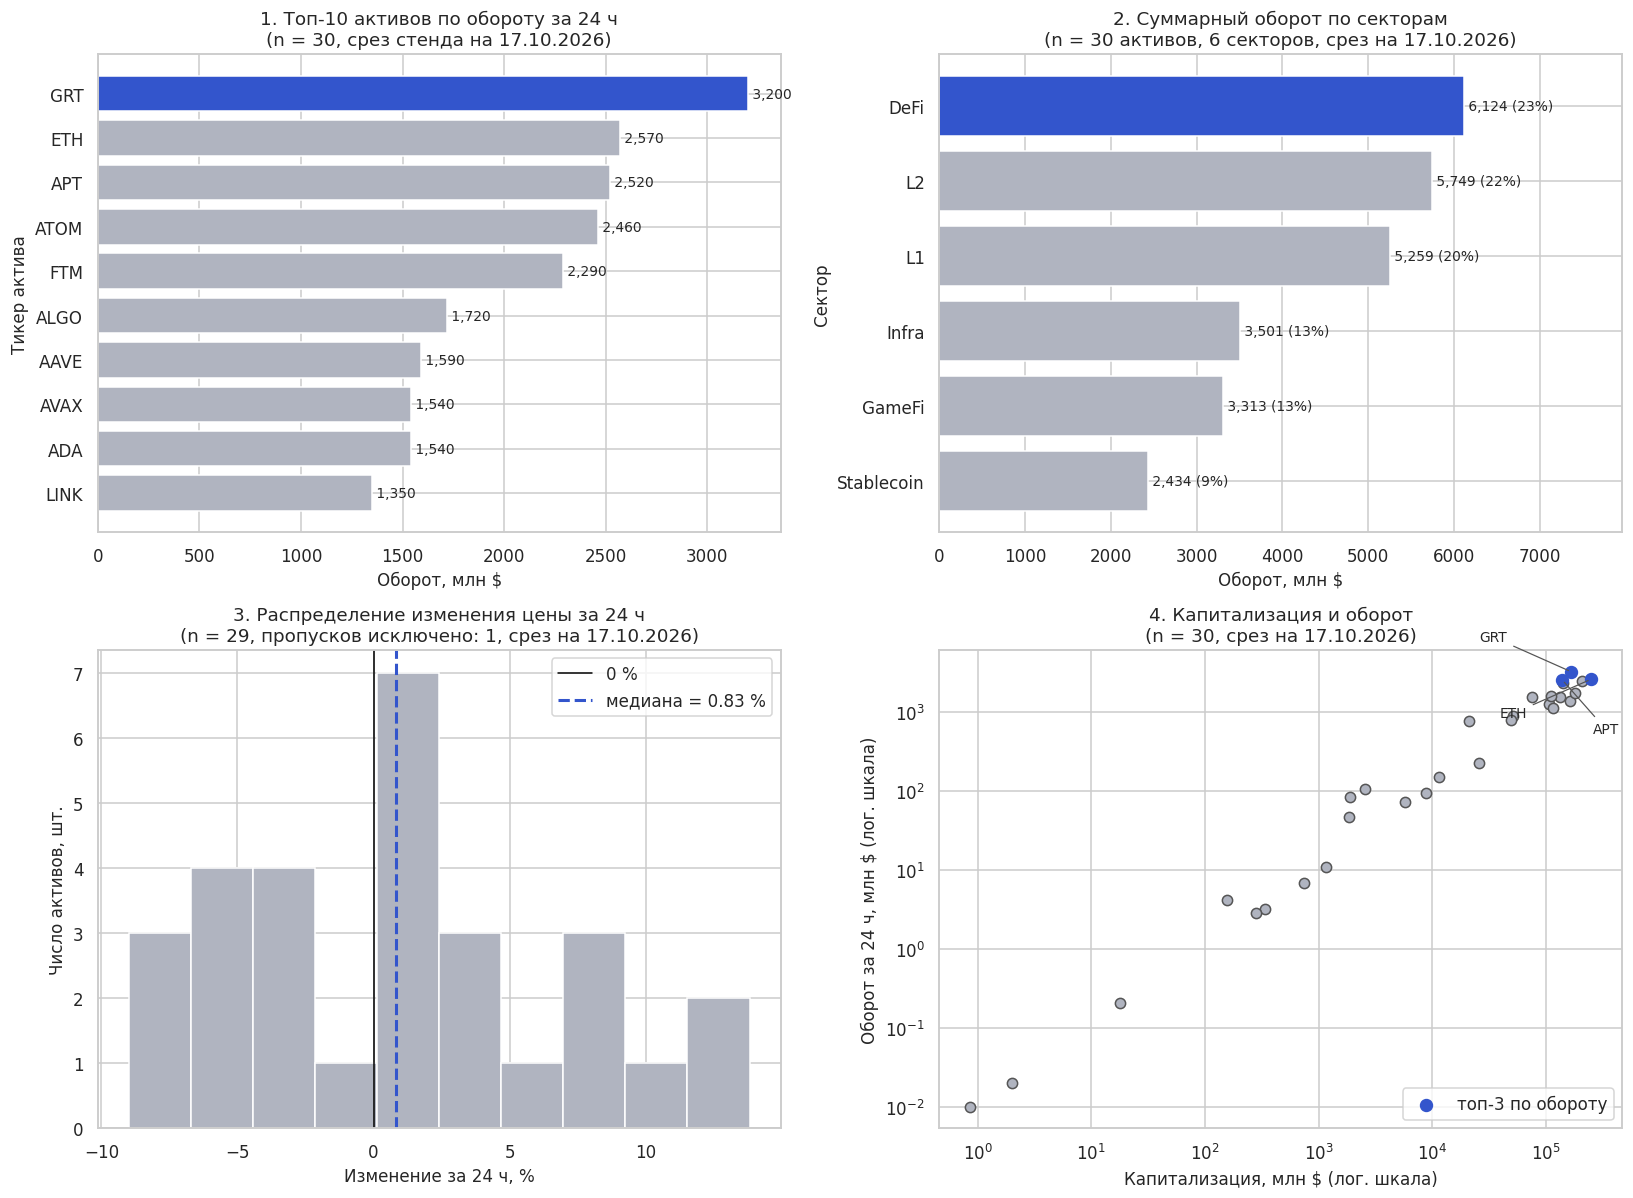

In [8]:
#@title Шаг 7. Бизнес-анализ и визуализация { display-mode: "form" }
# ------------------------------------------------------------------ TODO 7.1
# Постройте четыре содержательных графика по доступным данным своего варианта.
# Примеры: топ по числовому показателю, распределение значений, сравнение категорий,
# связь двух показателей. Отсутствующие предметные метрики не выдумывать.
# Требования: заголовок с объёмом выборки, подписи осей с единицами измерения, читаемый шрифт,
# единая палитра, отсутствие «мусорных» подписей.


# Доступные поля для построения графиков: оборот (volume), капитализация (mcap), изменение за 24 ч (change), сектор.
ACCENT, NEUTRAL = "#3355cc", "#b0b4c0"
SNAPSHOT = datetime.now().strftime("%d.%m.%Y")
plt.rcParams.update({"font.size": 10})

n_all = len(df)
d = df.copy()
d["volume_mln"] = d["volume_value"] / 1e6
d["mcap_mln"] = d["mcap_value"] / 1e6

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# График 1. Топ-10 активов по обороту
top10 = d.nlargest(10, "volume_value").sort_values("volume_value")
colors = [ACCENT if t == top10["ticker"].iloc[-1] else NEUTRAL for t in top10["ticker"]]
ax = axes[0, 0]
ax.barh(top10["ticker"], top10["volume_mln"], color=colors)
for y, v in enumerate(top10["volume_mln"]):
    ax.text(v, y, f" {v:,.0f}", va="center", fontsize=9)
ax.set_title(f"1. Топ-10 активов по обороту за 24 ч\n(n = {n_all}, срез стенда на {SNAPSHOT})")
ax.set_xlabel("Оборот, млн $")
ax.set_ylabel("Тикер актива")

# График 2. Оборот по секторам (сравнение категорий)
sec = d.groupby("sector")["volume_mln"].sum().sort_values()
share = sec / sec.sum()
ax = axes[0, 1]
ax.barh(sec.index, sec.values, color=[ACCENT if s == sec.index[-1] else NEUTRAL for s in sec.index])
for y, (v, sh) in enumerate(zip(sec.values, share.values)):
    ax.text(v, y, f" {v:,.0f} ({sh:.0%})", va="center", fontsize=9)
ax.set_title(f"2. Суммарный оборот по секторам\n(n = {n_all} активов, 6 секторов, срез на {SNAPSHOT})")
ax.set_xlabel("Оборот, млн $")
ax.set_ylabel("Сектор")
ax.set_xlim(0, sec.max() * 1.3)

# График 3. Распределение изменения цены за 24 ч
chg = d["change_24h"].dropna() * 100
ax = axes[1, 0]
ax.hist(chg, bins=10, color=NEUTRAL, edgecolor="white")
ax.axvline(0, color="black", lw=1, label="0 %")
ax.axvline(chg.median(), color=ACCENT, lw=2, ls="--", label=f"медиана = {chg.median():.2f} %")
ax.set_title(f"3. Распределение изменения цены за 24 ч\n(n = {len(chg)}, пропусков исключено: {n_all - len(chg)}, срез на {SNAPSHOT})")
ax.set_xlabel("Изменение за 24 ч, %")
ax.set_ylabel("Число активов, шт.")
ax.legend()

# График 4. Капитализация против оборота
ax = axes[1, 1]
ax.scatter(d["mcap_mln"], d["volume_mln"], color=NEUTRAL, edgecolor="#555", s=45)
lead = d.nlargest(3, "volume_value")
ax.scatter(lead["mcap_mln"], lead["volume_mln"], color=ACCENT, s=60, label="топ-3 по обороту")
for (_, r), off in zip(lead.iterrows(), [(-60, 20), (-60, -25), (20, -35)]):   # разносим подписи
    ax.annotate(r["ticker"], (r["mcap_mln"], r["volume_mln"]), xytext=off, textcoords="offset points",
                fontsize=9, arrowprops={"arrowstyle": "-", "color": "#555", "lw": 0.8})
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title(f"4. Капитализация и оборот\n(n = {n_all}, срез на {SNAPSHOT})")
ax.set_xlabel("Капитализация, млн $ (лог. шкала)")
ax.set_ylabel("Оборот за 24 ч, млн $ (лог. шкала)")
ax.legend(loc="lower right")

plt.tight_layout()
fig.savefig(WORK_DIR / "charts.png", dpi=130, bbox_inches="tight")
plt.show()
PLOTS_DONE = True

# ------------------------------------------------------------------ TODO 7.2
# Сформируйте текстовый отчёт для ЛПР: что собрано, три наблюдения с числами,
# два-три управленческих решения с ожидаемым эффектом и способом проверки.

В стенде нет цен bid/ask и разбивки по биржам, поэтому спред не рассчитывается.
Вместо него анализируются доступные поля: оборот, капитализация, изменение за 24 ч, сектор.

Наблюдения:
1. Концентрация оборота: топ-3 актива дают 31.4% суммарного оборота
   (26,380 млн $); лидер: GRT (3,200 млн $).
2. Сектор с наибольшим оборотом — DeFi: 23.2% от общего оборота.
3. Изменение за 24 ч: медиана +0.83%, растут 59% активов, разброс от -8.99% до +13.82%.

Рекомендации:
1. Направлять крупные ордера в первую очередь на активы из топ-3 по обороту: там глубже ликвидность и ниже ожидаемое проскальзывание.
2. Для активов с оборотом ниже медианы (494.9 млн $) ограничить
   размер одного ордера и дробить его.

**Как интерпретировать результат.** Сначала назовите фактически рассчитанные показатели, размер выборки и тип учебных данных. Затем объясните, какие различия между позициями или категориями они показывают. **Не утверждайте**, что выявлены реальные складские дефициты, инвестиционные раунды, биржевые риски или продажи, если таких сведений в стенде нет. Практическую рекомендацию формулируйте как **решение на основе учебной модели**, а необходимые для реального применения дополнительные данные перечислите отдельно.


## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; параметры подставляются в код автоматически по значению `VARIANT`. Столбец «Профиль стенда» задаёт набор данных учебной витрины — это обязательная часть работы. Столбцы «Реальная площадка» и «Легальный источник» относятся к краткой исследовательской части, **без обязательного сбора с внешнего сайта**. Достаточно описать ограничения автоматизированного доступа, возможный XHR/API (если он публично доступен и удалось его установить) и разрешённые аналоги. Аналитическая задача указывает бизнес-контекст: если отдельных показателей нет в учебном стенде, используйте доступные поля и явно объясните ограничение.

| № | Доменная область | Профиль стенда | Реальная площадка (разбор ограничений) | Легальный источник тех же данных | Аналитическая задача и решение |
|---:|---|---|---|---|---|
| 1 | Криптовалютный арбитраж | `crypto` | CoinMarketCap — раздел Cryptocurrencies | CoinGecko API (/coins/markets) | Топ-10 по обороту, разброс суточного изменения; решение: где держать лимиты маркет-мейкера |
| 2 | Фондовые индексы АТР | `stocks` | Investing.com — Asia/Pacific indices | MOEX ISS API, Alpha Vantage | Сравнение доходностей, когорты роста и падения; решение: ребалансировка регионального портфеля |
| 3 | Мониторинг цен на технологические металлы | `metals` | Trading Economics — Commodities | World Bank Commodity Price Data (Pink Sheet) | Топ по обороту и волатильности; решение: сроки хеджирования закупок |
| 4 | Ценовая разведка маркетплейса: смартфоны | `ecom` | Агрегатор цен категории «Смартфоны» | Открытые фиды поставщиков, API маркетплейса продавца | Ценовые сегменты и доля дефицита; решение: цена входа в категорию |
| 5 | Трекинг раундов венчурных сделок | `startups` | Crunchbase — Funding Rounds | OpenAlex, Dealroom API (по подписке), данные ЕГРЮЛ | Распределение размеров раундов, топ-инвесторы; решение: фокус отраслевого фонда |
| 6 | Ликвидность DeFi-протоколов | `crypto` | DeFiLlama — TVL rankings | DefiLlama API (открытый) | TVL и оборот в логарифмических шкалах; решение: лимиты на протокол |
| 7 | Голубые фишки российского рынка | `stocks` | Investing.com — Russian stocks | MOEX ISS API (iss.moex.com) | Топ по обороту, медиана изменения; решение: состав торговой корзины дня |
| 8 | Драгоценные металлы и хеджирование | `metals` | Kitco — Live spot prices | LBMA открытые котировки, ЦБ РФ учётные цены | Динамика и разброс; решение: доля металлов в резерве |
| 9 | Мониторинг цен на ноутбуки | `ecom` | Витрина категории «Ноутбуки» | API прайс-агрегатора продавца | Медианы по сегментам, ценовые кластеры; решение: позиционирование новой линейки |
| 10 | Скоринг стартап-экосистемы региона | `startups` | Dealroom — региональные дашборды | OpenAlex, Росстат, ЕГРЮЛ | Когорты по темпу роста; решение: приоритеты акселератора |
| 11 | Стейблкоины и риск депега | `crypto` | CoinMarketCap — Stablecoins | CoinGecko API | Отклонение от номинала, объёмы; решение: лимиты казначейства |
| 12 | Европейские индексы и открытие торгов | `stocks` | Investing.com — European indices | Alpha Vantage, Stooq | Утренние гэпы, распределение; решение: тайминг заявок |
| 13 | Аккумуляторные металлы и цепочка поставок | `metals` | SMM — Battery metals | USGS Mineral Commodity Summaries | Волатильность лития и кобальта; решение: пересмотр закупочных контрактов |
| 14 | Бытовая техника: акции конкурентов | `ecom` | Витрина категории «Бытовая техника» | Фиды партнёрских программ | Глубина скидок, доля позиций в наличии; решение: календарь промо |
| 15 | FinTech-стартапы: динамика найма | `startups` | AngelList / Wellfound — Jobs | «Работа в России» (opendata.trudvsem.ru) | Число вакансий против оценки; решение: выбор объекта для partnership |
| 16 | NFT и игровые токены | `crypto` | CoinGecko — Gaming category | CoinGecko API | Топ по обороту, хвосты распределения; решение: отсев неликвида |
| 17 | Азиатские IT-эмитенты | `stocks` | Yahoo Finance — Screener | Alpha Vantage, Nasdaq Data Link | Капитализация против оборота; решение: включение в watchlist |
| 18 | Редкоземельные элементы и импортозависимость | `metals` | Trading Economics — Rare earth | USGS, World Bank | Топ по цене и изменение; решение: стратегический запас |
| 19 | Аудиотехника: ассортиментная матрица | `ecom` | Витрина категории «Аудио» | API маркетплейса продавца | Медиана цены по секторам; решение: сокращение хвоста SKU |
| 20 | HealthTech: инвестиционная активность | `startups` | Crunchbase — HealthTech | OpenAlex, ClinicalTrials.gov API | Размер раунда и стадия; решение: вход в нишу |
| 21 | Кросс-биржевой спред по BTC | `crypto` | CoinMarketCap — Markets | Binance и Bybit публичные API | Спреды и обороты по площадкам; решение: маршрутизация ордеров |
| 22 | Дивидендные истории рынка РФ | `stocks` | Smart-lab — Дивиденды | MOEX ISS API | Доходность против капитализации; решение: дивидендный портфель |
| 23 | Промышленные металлы и энергопереход | `metals` | LME — Metals prices | World Bank Pink Sheet, ЦБ РФ | Когорты роста и падения; решение: индексация контрактов |
| 24 | Маркетплейс: мониторинг дефицита | `ecom` | Витрина «Все товары» | API продавца, фиды поставщиков | Доля отсутствующих позиций; решение: перераспределение закупки |
| 25 | EdTech: выручка и раунды | `startups` | HolonIQ — EdTech dashboards | OpenAlex, открытые отчёты фондов | Топ по оценке; решение: сделки M&A |
| 26 | Крипто-инфраструктура: L2-решения | `crypto` | L2BEAT — Scaling | L2BEAT API, DefiLlama API | TVL и рост; решение: выбор сети для интеграции |
| 27 | Американские техгиганты | `stocks` | Yahoo Finance — Most active | Alpha Vantage, Finnhub | Оборот и изменение; решение: наблюдение за концентрацией |
| 28 | Строительные материалы: индекс цен | `metals` | Trading Economics — Steel | Росстат, World Bank | Медианы и разброс; решение: бюджет строительного проекта |
| 29 | Недвижимость: мониторинг предложений | `ecom` | Агрегатор объявлений недвижимости | Открытые данные Росреестра, ЕМИСС | Распределение цен, когорты; решение: цена входа на локальный рынок |
| 30 | Комплексный мониторинг рыночной витрины (эталон) | `crypto` | CoinMarketCap — Cryptocurrencies | CoinGecko API (/coins/markets) | Топ-10 по обороту с выделением лидера, распределение изменения за 24 ч, когорты роста и падения, капитализация против оборота; решение: где концентрировать лимиты и что проверить до прогноза |

Минимум для зачёта по сбору: **все 30 позиций учебной витрины** (подгрузка работает), не менее **90 % распознанных значений** в предусмотренных самопроверкой колонках `volume_value` и `mcap_value`, **четыре содержательных графика по доступным полям** и управленческие выводы. В колонках `price_value` и `change_24h` намеренно встречаются пропуски: сохраняйте их как пропуски, а не как нули. Расчёт отсутствующих в стенде предметных метрик и парсинг внешнего сайта **не являются обязательными**.

## Критерии оценивания

**Единые для всех вариантов:** оценка выставляется по выполненным этапам на учебном стенде. Не снижаются баллы за отсутствие парсинга внешнего сайта и показателей, для которых в стенде не предусмотрены исходные данные; обязательны корректные альтернативные показатели и пояснение ограничений.

### Балльная структура (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Окружение и запуск браузера | Корректная установка, флаги `--no-sandbox` и `--disable-dev-shm-usage`, реалистичный контекст, блокировка лишних ресурсов | 1,0 |
| 2. Обход препятствий | Закрытие cookie-баннера и модальных окон каскадом селекторов; работа при отсутствии баннера | 1,0 |
| 3. Ожидания | Явные ожидания вместо `time.sleep`; ожидание по числу строк при догрузке; корректный таймаут | 1,5 |
| 4. XPath и сбор | Устойчивые селекторы (`data-testid`, `contains`, оси), полнота выборки, разделение «браузер → HTML → lxml» | 2,0 |
| 5. Очистка и Excel | Суффиксы K/M/B, проценты долями, валюта, даты, пропуски как `NaN`; тесты функций; оформленная выгрузка | 2,0 |
| 6. Аналитика и графики | Четыре графика по доступным показателям варианта, корректные метрики, оформление | 1,5 |
| 7. Бизнес-вывод | 3 наблюдения с числами, 2–3 рекомендации, ограничения данных и краткий разбор реальной площадки | 1,0 |

### Шкала

| Баллы | Оценка | Содержательный смысл |
|---|---|---|
| 9,0–10,0 | **A** (отлично) | Скрипт устойчив, селекторы надёжны, очистка полная, выводы управленческие |
| 8,0–<9,0 | **B** (хорошо) | Данные собраны и очищены, есть шероховатости в обработке ошибок или оформлении |
| 7,0–<8,0 | **C** (удовлетворительно) | Сбор работает только «на удачном прогоне», ожидания частично на паузах |
| 6,0–<7,0 | **D** (зачтено с замечаниями) | Данные собраны неполно либо очистка теряет часть значений |
| <6,0 | **F** (не зачтено) | Скрипт не воспроизводится, данные собраны вручную или подменены |

### Требования к отказоустойчивости

Скрипт обязан переживать без падения ноутбука:

1. **Таймаут ожидания** (`TimeoutError` / `TimeoutException`) — перехват, сохранение скриншота и HTML, понятное сообщение о вероятной причине.
2. **Пустую выборку** — проверка `len(rows) == 0` до перехода к анализу, с указанием, какой селектор не сработал.
3. **Отсутствие оверлея** — отсутствие баннера не должно приводить к исключению.
4. **Частично заполненную строку** — отсутствующая ячейка даёт `None`, а не обрывает цикл.
5. **Нераспознанное значение** — `n/a`, `—`, пустая строка превращаются в `NaN`, но строка остаётся в выборке.
6. **Ограничение цикла догрузки** — максимальное число кликов и условие выхода при отсутствии роста.

### Требования к оформлению графиков

* заголовок с указанием объёма выборки (`n = …`) и периода;
* подписи обеих осей с единицами измерения (млн ₽, %, шт.);
* шрифт не мельче 9 пт, отсутствие наложения подписей;
* единая палитра: один акцентный цвет для выделяемой категории, нейтральный — для остальных; зелёный и красный только по смыслу «рост/падение»;
* опорные линии (ноль, медиана, порог) там, где они помогают читать график;
* логарифмическая шкала, если значения различаются на порядки, с явной пометкой в подписи оси;
* никаких «радужных» палитр на категориальных данных и трёхмерных эффектов.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| `time.sleep()` вместо явных ожиданий в сценарии сбора | −1,0 |
| Данные получены вручную (скопированы), а не собраны скриптом | −4,0 |
| Попытка обхода капчи, Cloudflare или сбор за логином | работа не принимается |
| Сбор персональных данных | работа не принимается |
| Нет обработки исключений при сборе | −1,0 |
| Проценты сохранены как 2.5 вместо 0.025 или пропуски заменены нулями | −1,0 |
| Графики без подписей осей и единиц измерения | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |

### Перед самопроверкой

Убедитесь, что `raw_df` содержит 30 строк; функции очистки проходят тесты; Excel и `page.png` сохранены в `WORK_DIR`; четыре графика и выводы присутствуют в ноутбуке. **Скриншот после успешного сбора** добавьте в TODO 5.2 самостоятельно, так как автоматическое сохранение в заготовке описано только для таймаута.

Встроенная проверка **не является автоматическим выставлением оценки**. Её пункт «Явные ожидания вместо пауз» зависит от `COLLECT_SOURCE` (переменная не задаётся автоматически исходным шаблоном), а проверка графиков — от наличия открытых рисунков или `PLOTS_DONE`. Поэтому при ложном отрицательном результате приложите корректный код и сохранённые графики; **преподаватель оценивает фактическое выполнение**, а не только количество галочек. Исполняемую ячейку проверки изменять не требуется.


In [11]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Браузер стартовал и страница открылась", bool(html) and len(html) > 1000)
check("Cookie-баннер обработан (или его не было)", "cookie-banner" not in html or USE_LIVE_TARGET,
      "баннер остался в DOM — клик не сработал")
check("Собраны все строки витрины (≥ 30)", len(raw_df) >= 30,
      "не отработала догрузка по кнопке «Показать ещё»")
check("Числовые поля распознаны не хуже 90 %",
      df["volume_value"].notna().mean() >= 0.9 and df["mcap_value"].notna().mean() >= 0.9)
check("Проценты приведены к долям единицы",
      df["change_24h"].dropna().abs().max() < 1.5 if df["change_24h"].notna().any() else False,
      "значение вроде 2.5 вместо 0.025 — забыли поделить на 100")
check("Пропуски не превратились в нули",
      df["price_value"].isna().sum() > 0 or df["change_24h"].isna().sum() > 0,
      "на стенде есть 'n/a' и '—': они должны остаться пропусками")
check("Файл Excel выгружен", EXCEL_PATH.exists() and EXCEL_PATH.stat().st_size > 4000)
check("Скриншот страницы сохранён как доказательство сбора", (WORK_DIR / "page.png").exists())
check("Явные ожидания вместо пауз", "time.sleep" not in globals().get("COLLECT_SOURCE", "time.sleep"),
      "уберите time.sleep из сценария сбора")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False),
      "выполните шаг 7 до самопроверки")

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Браузер стартовал и страница открылась
  ✅ Cookie-баннер обработан (или его не было)
  ✅ Собраны все строки витрины (≥ 30)
  ✅ Числовые поля распознаны не хуже 90 %
  ✅ Проценты приведены к долям единицы
  ✅ Пропуски не превратились в нули
  ✅ Файл Excel выгружен
  ✅ Скриншот страницы сохранён как доказательство сбора
  ✅ Явные ожидания вместо пауз
  ✅ Построены графики


## Дополнительное задание со звёздочкой (необязательно, до +2 баллов)

Выберите **одно** из предложенных ниже направлений и представьте воспроизводимый результат и его интерпретацию. Дополнительное задание не заменяет обязательные этапы ЛР1. Базовая шкала работы — **10 баллов**; дополнительные баллы рассматриваются преподавателем отдельно с учётом принятой в LMS максимальной оценки.


In [ ]:
#@title Задание со звёздочкой (до +2 балла) { display-mode: "form" }
# A. Перехват сетевых запросов вместо разбора DOM.
#    Повесьте page.on("response", ...) и найдите XHR/fetch, который отдаёт те же данные в JSON.
#    Сравните время сбора и устойчивость двух подходов и объясните, когда DOM всё же необходим.
#
# B. Бесконечная прокрутка.
#    Замените кнопку «Показать ещё» на прокрутку (page.mouse.wheel) и реализуйте корректное
#    условие остановки: высота документа перестала расти в течение N итераций.
#
# C. Параллельный сбор.
#    Соберите пять профилей стенда одновременно через asyncio.gather и несколько контекстов.
#    Измерьте ускорение и объясните, почему контекстов должно быть больше, чем браузеров.
#
# D. Устойчивость к смене вёрстки.
#    Реализуйте «каскад селекторов»: data-testid → семантический XPath → текстовый поиск,
#    и тесты, которые ломают разметку (удалён атрибут, переименован класс).
#
# E. Мониторинг и сравнение срезов.
#    Сохраняйте снимки в parquet с меткой времени, реализуйте второй запуск и таблицу изменений:
#    новые позиции, изменение цены и оборота, выбывшие позиции.